In [44]:
import pandas as pd
import seaborn as sns
import seaborn.objects as so
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

from matplotlib.cm import ScalarMappable

In [45]:
sns.set(font="Arial")

In [46]:
metadata = pd.read_csv('metadata_MSK.csv')
metadata

,enzyme,path
0,AspN,data/MSK/AspN/protein.tsv
1,GluC,data/MSK/GluC/protein.tsv
2,Trypsin,data/MSK/Trypsin/protein.tsv
3,LysC,data/MSK/LysC/protein.tsv
4,LysN,data/MSK/LysN/protein.tsv
5,ArgC,data/MSK/ArgC/protein.tsv
6,Chymotrypsin,data/MSK/Chymotrypsin/protein.tsv
7,Proalanase,data/MSK/Proalanase/protein.tsv


In [47]:
def normalize(df, sample_name):
    '''
    Returns  NSAF (Normalized Spectral Abundance Factor) instead of raws
		'''
    spectrum_count_colum = 'Razor Spectral Count'
    df_nsaf = df.copy()
    df_nsaf[f'SC/L {sample_name}'] = df_nsaf['Razor Spectral Count'] / df_nsaf['Length']
    df_nsaf[f'{sample_name}'] = df_nsaf[f'SC/L {sample_name}'] / df_nsaf[f'SC/L {sample_name}'].sum()
    return df_nsaf

In [48]:
aspn = pd.read_csv(metadata['path'][0], sep='\t')
gluc = pd.read_csv(metadata['path'][1], sep='\t')
trypsin = pd.read_csv(metadata['path'][2], sep='\t')
lysc = pd.read_csv(metadata['path'][3], sep='\t')
lysn = pd.read_csv(metadata['path'][4], sep='\t')
argc = pd.read_csv(metadata['path'][5], sep='\t')
chymotrypsin = pd.read_csv(metadata['path'][6], sep='\t')
proalanase = pd.read_csv(metadata['path'][7], sep='\t')

In [49]:
aspn_nsaf = normalize(aspn, 'AspN')
gluc_nsaf = normalize(gluc, 'GluC')
trypsin_nsaf = normalize(trypsin, 'Trypsin')
lysc_nsaf = normalize(lysc, 'LysC')
lysn_nsaf = normalize(lysn, 'LysN')
argc_nsaf = normalize(argc, 'ArgC')
chymotrypsin_nsaf = normalize(chymotrypsin, 'Chymotrypsin')
proalanase_nsaf = normalize(proalanase, 'Proalanase')

In [50]:
aspn_nsaf = aspn_nsaf[~aspn_nsaf['Indistinguishable Proteins'].str.contains('sp|', regex=False).fillna(False)]
gluc_nsaf = gluc_nsaf[~gluc_nsaf['Indistinguishable Proteins'].str.contains('sp|', regex=False).fillna(False)]
trypsin_nsaf = trypsin_nsaf[~trypsin_nsaf['Indistinguishable Proteins'].str.contains('sp|', regex=False).fillna(False)]
lysc_nsaf = lysc_nsaf[~lysc_nsaf['Indistinguishable Proteins'].str.contains('sp|', regex=False).fillna(False)]
lysn_nsaf = lysn_nsaf[~lysn_nsaf['Indistinguishable Proteins'].str.contains('sp|', regex=False).fillna(False)]
argc_nsaf = argc_nsaf[~argc_nsaf['Indistinguishable Proteins'].str.contains('sp|', regex=False).fillna(False)]
chymotrypsin_nsaf = chymotrypsin_nsaf[~chymotrypsin_nsaf['Indistinguishable Proteins'].str.contains('sp|', regex=False).fillna(False)]
proalanase_nsaf = proalanase_nsaf[~proalanase_nsaf['Indistinguishable Proteins'].str.contains('sp|', regex=False).fillna(False)]

In [51]:
nc = aspn_nsaf[['Protein', 'SC/L AspN', 'AspN']].merge(
		gluc_nsaf[['Protein', 'SC/L GluC', 'GluC']], on='Protein', how='outer').merge(
		trypsin_nsaf[['Protein', 'SC/L Trypsin', 'Trypsin']], on='Protein', how='outer').merge(
    lysc_nsaf[['Protein', 'SC/L LysC', 'LysC']], on='Protein', how='outer').merge(
    lysn_nsaf[['Protein', 'SC/L LysN', 'LysN']], on='Protein', how='outer').merge(
    argc_nsaf[['Protein', 'SC/L ArgC', 'ArgC']], on='Protein', how='outer').merge(
    chymotrypsin_nsaf[['Protein', 'SC/L Chymotrypsin', 'Chymotrypsin']], on='Protein', how='outer').merge(
    proalanase_nsaf[['Protein', 'SC/L Proalanase', 'Proalanase']], on='Protein', how='outer').fillna(0)

In [52]:
nc.columns

Index(['Protein', 'SC/L AspN', 'AspN', 'SC/L GluC', 'GluC', 'SC/L Trypsin',
       'Trypsin', 'SC/L LysC', 'LysC', 'SC/L LysN', 'LysN', 'SC/L ArgC',
       'ArgC', 'SC/L Chymotrypsin', 'Chymotrypsin', 'SC/L Proalanase',
       'Proalanase'],
      dtype='object')

In [53]:
meta = pd.read_csv('data/meta/20260219_EwS_ncORF_metadata_summary.tsv', sep='\t')
meta

,orf_id,ORF_ranges,Protein,gene_id,gene_biotype,gene_name,transcript_id,uniprot_gn_ids,cl_mean,ps_mean,...,Number_SB,Peptides_WB,Number_WB,class,any_peptide_found_in_IP,result_A673,result_SKNMC,result_MHHES,result_TC106,result_RDES
0,ENSG00000159167__ENST00000290271__uORF__2__GTG,8:23854633-23854746,MAAAAAAAAAAAAAEAPVAAAASPATTTKKNPHQILT,ENSG00000159167,protein_coding,STC1,ENST00000290271,A0A0H3W641;P52823,1.187192,2.508946,...,NaN,NaN,NaN,0.0,False,not expressed,not expressed,upregulated,ns,ns
1,ENST00000291041_23_121,16:67893276-67908682,MAAAAAAAAAAAIARRWPAEPPRRRRARRPREV,ENSG00000159792,protein_coding,PSKH1,ENST00000291041,P11801;A0A087WZT9,23.079040,17.597305,...,NaN,NaN,NaN,1.0,True,ns,ns,ns,ns,ns
2,ENST00000216727_182_1099,14:23321470-23325283,MAAAAAAAAAAGAAGGRGSGPGRRRHLVPGAGGEAGEGAPGGAGDY...,ENSG00000100836,protein_coding,PABPN1,ENST00000216727,B4DEH8;Q86U42;G3V4T2,72.570950,51.634440,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,ENST00000397276_14_901,14:23321470-23324296,MAAAAAAAAAAGAAGGRGSGPGRRRHLVPGAGGEAGEGAPGGAGDY...,ENSG00000100836,protein_coding,PABPN1,ENST00000397276,B4DEH8;Q86U42;G3V4T2,71.136807,50.211111,...,NaN,NaN,NaN,NaN,NaN,ns,ns,ns,ns,ns
4,ENST00000354300_17_85,12:110583234-110583302,MAAAAAAAAAGTSVGLRRRSRRF,ENSG00000196850,protein_coding,PPTC7,ENST00000354300,Q8NI37,14.741234,14.913901,...,NaN,NaN,NaN,0.0,False,not expressed,ns,upregulated,ns,ns
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
62178,ENSG00000116604__TCONS_00065632__ncRNA__9__ATT,1:156483398-156500599,MYYSPRPELRLPGVEDPPDQGRGLPALCRDNTVPPAGLEAVQKVSCRP,ENSG00000116604,protein_coding,MEF2D,TCONS_00065632,Q14814;Q05BX2,12.438524,33.178861,...,NaN,NaN,NaN,0.0,False,ns,ns,ns,ns,ns
62179,ENST00000552151_8_454,12:70310970-70330470,MYYSQSSMFPHRSEKDMLASPSTSGQLSQFGASLYGQQSALGLPMR...,ENSG00000111596,protein_coding,CNOT2,ENST00000552151,F8VSK9;Q9NZN8;F8VUB4;F8W145;F8VPX5;F8VVY1;F8VV...,12.182117,23.360930,...,NaN,NaN,NaN,NaN,NaN,ns,ns,ns,ns,ns
62180,ENST00000495930_268_459,13:112875798-112875989,MYYVFIQMLSSGPAWLAIVLLVTISLLPDVLKKVLCRQLWPTATER...,ENSG00000068650,protein_coding,ATP11A,ENST00000495930,P98196;E9PEJ6;A2A3G9;A0A087WVE8,6.739418,19.103163,...,NaN,NaN,NaN,NaN,NaN,not expressed,ns,ns,ns,ns
62181,ENSG00000181392_ENSG00000239382__ENST000004904...,19:36010923-36013077,MYYVPDFISKEEEEYLLRQVFNAPKPKWTQLSGRKLQNWGPHCLPQ...,ENSG00000239382,protein_coding,ALKBH6,ENST00000490483,Q3KRA9;E9PI76;S4R3C7;H0YD83,10.796175,7.697037,...,NaN,NaN,NaN,NaN,NaN,ns,ns,ns,ns,ns


In [54]:
nc['Protein'] = nc['Protein'].str.replace('_NEOTRANSCRIPT', '', regex=False)
nc

,Protein,SC/L AspN,AspN,SC/L GluC,GluC,SC/L Trypsin,Trypsin,SC/L LysC,LysC,SC/L LysN,LysN,SC/L ArgC,ArgC,SC/L Chymotrypsin,Chymotrypsin,SC/L Proalanase,Proalanase
0,A673_00003209_469_2553,0.056115,0.000135,0.053237,0.000097,0.090647,0.000047,0.069065,0.00005,0.041727,0.00005,0.008633,0.000014,0.034532,0.000033,0.000000,0.000000
1,ENSG00000006125_ENSG00000270647__ENST000006189...,0.006543,0.000016,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2,ENSG00000010803__ENST00000372595__Variant__1__ATA,0.009023,0.000022,0.000000,0.000000,0.033083,0.000017,0.000000,0.00000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
3,ENSG00000023734__ENST00000419869__Trunc__0__ATT,0.006689,0.000016,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
4,ENSG00000026025__TCONS_00102651__ncRNA__0__ACG,0.881188,0.002123,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9753,sp|A0A0B4J279|TVA21_HUMAN,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.008929,0.000043
9754,sp|Q9ULD9|ZN608_HUMAN,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.001323,0.000006
9755,sp|Q7Z4B0-2|CR020_HUMAN,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.010309,0.000049
9756,ENST00000160740_710_5503,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.004380,0.000021


In [55]:
merge_nc = nc.merge(meta, left_on='Protein', right_on='orf_id', how='left')
merge_nc

,Protein_x,SC/L AspN,AspN,SC/L GluC,GluC,SC/L Trypsin,Trypsin,SC/L LysC,LysC,SC/L LysN,...,Number_SB,Peptides_WB,Number_WB,class,any_peptide_found_in_IP,result_A673,result_SKNMC,result_MHHES,result_TC106,result_RDES
0,A673_00003209_469_2553,0.056115,0.000135,0.053237,0.000097,0.090647,0.000047,0.069065,0.00005,0.041727,...,NaN,NaN,NaN,NaN,NaN,ns,ns,ns,ns,ns
1,ENSG00000006125_ENSG00000270647__ENST000006189...,0.006543,0.000016,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,...,NaN,NaN,NaN,NaN,NaN,ns,ns,ns,downregulated,ns
2,ENSG00000010803__ENST00000372595__Variant__1__ATA,0.009023,0.000022,0.000000,0.000000,0.033083,0.000017,0.000000,0.00000,0.000000,...,NaN,NaN,NaN,NaN,NaN,ns,ns,downregulated,ns,downregulated
3,ENSG00000023734__ENST00000419869__Trunc__0__ATT,0.006689,0.000016,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,...,NaN,NaN,NaN,NaN,NaN,ns,ns,ns,ns,ns
4,ENSG00000026025__TCONS_00102651__ncRNA__0__ACG,0.881188,0.002123,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,...,NaN,NaN,NaN,NaN,NaN,ns,ns,upregulated,upregulated,upregulated
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9753,sp|A0A0B4J279|TVA21_HUMAN,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9754,sp|Q9ULD9|ZN608_HUMAN,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9755,sp|Q7Z4B0-2|CR020_HUMAN,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9756,ENST00000160740_710_5503,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,...,NaN,NaN,NaN,NaN,NaN,ns,ns,upregulated,ns,ns


In [56]:
merge_nc['neotranscript_orf_type'] = merge_nc['neotranscript_orf_type'].fillna('Canonical_protein')
merge_nc['orf_category_new'] =  merge_nc['orf_category_new'].fillna('Canonical_protein')

In [57]:
merge_nc['orf_category_new'].value_counts()

orf_category_new
Canonical_protein    8293
ORF_variant          1352
pseudogene ORF         51
uoORF                  18
uORF                   17
intORF                 12
dORF                    6
lncRNA ORF              5
neogene ORF             2
doORF                   2
Name: count, dtype: int64

In [58]:
merge_nc['neotranscript_orf_type'].value_counts()

neotranscript_orf_type
Canonical_protein            8293
ORF_variant                  1343
Non-canonical ORF general     111
In-frame ORF                    9
Neogene ORF                     2
Name: count, dtype: int64

In [59]:
merge_nc['orf_cathegoty_toplot'] = merge_nc['neotranscript_orf_type'].where(merge_nc['neotranscript_orf_type'] != 'Non-canonical ORF general', merge_nc['orf_category_new'])

In [60]:
merge_nc['orf_cathegoty_toplot'].value_counts()

orf_cathegoty_toplot
Canonical_protein    8293
ORF_variant          1343
pseudogene ORF         51
uoORF                  18
uORF                   17
intORF                 12
In-frame ORF            9
dORF                    6
lncRNA ORF              5
Neogene ORF             2
doORF                   2
Name: count, dtype: int64

In [61]:
palette = {
    "Neogene ORF": "#1b365d",
    "In-frame ORF": "#6ea9d2",
    "ORF_variant": "#FFB347",
    "Canonical_protein": "#77DD77",
    "lncRNA ORF": "#D32F2F",
    "dORF": "#32936F",
    "doORF": "#80baa5",
    "intORF": "#d9d9d9",
    "uORF": "#6c57b7",
    "uoORF": "#a091d4",
    "pseudogene ORF": "#F15BB5"
}

In [62]:
merge_nc = merge_nc[(merge_nc['orf_cathegoty_toplot']!='Canonical_protein')&(merge_nc['orf_cathegoty_toplot']!='ORF_variant')]
merge_nc

,Protein_x,SC/L AspN,AspN,SC/L GluC,GluC,SC/L Trypsin,Trypsin,SC/L LysC,LysC,SC/L LysN,...,Peptides_WB,Number_WB,class,any_peptide_found_in_IP,result_A673,result_SKNMC,result_MHHES,result_TC106,result_RDES,orf_cathegoty_toplot
0,A673_00003209_469_2553,0.056115,0.000135,0.053237,0.000097,0.090647,0.000047,0.069065,0.000050,0.041727,...,NaN,NaN,NaN,NaN,ns,ns,ns,ns,ns,In-frame ORF
58,ENST00000438427_213_782,0.026316,0.000063,0.000000,0.000000,0.000000,0.000000,0.026316,0.000019,0.015789,...,NaN,NaN,0.0,False,not expressed,not expressed,ns,ns,ns,pseudogene ORF
70,ENST00000637660_1131_2294,0.010309,0.000025,0.100515,0.000183,0.250000,0.000130,0.023196,0.000017,0.000000,...,NaN,NaN,0.0,False,ns,ns,ns,ns,ns,intORF
2890,ENST00000420977_1_747,0.004016,0.000010,0.000000,0.000000,0.000000,0.000000,0.008032,0.000006,0.008032,...,NaN,NaN,0.0,False,ns,ns,ns,ns,ns,pseudogene ORF
2891,ENST00000444290_37_267,0.025974,0.000063,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,NaN,NaN,0.0,False,not expressed,ns,ns,ns,ns,pseudogene ORF
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9595,ENST00000447818_2495_2734,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,NaN,NaN,0.0,False,not expressed,ns,ns,ns,ns,pseudogene ORF
9647,ENSG00000170004__TCONS_00371015__ncRNA__38__ATA,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,NaN,NaN,0.0,False,not expressed,not expressed,ns,not expressed,not expressed,intORF
9650,ENSG00000139531__ENST00000356124__uoORF__3__ACG,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,NaN,NaN,0.0,False,not expressed,not expressed,ns,upregulated,ns,uoORF
9655,ENST00000347055_388_471,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,NaN,NaN,0.0,False,not expressed,ns,ns,ns,ns,uoORF


In [63]:
merge_nc = merge_nc[merge_nc['gene_name'] != 'H2BP2']

In [64]:
merge_nc.rename(columns={'Protein_x': 'Protein'}, inplace=True)

C:\Users\Masha\AppData\Local\Temp\ipykernel_11880\563811387.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  merge_nc.rename(columns={'Protein_x': 'Protein'}, inplace=True)


In [65]:
ncORFs_detected_MSK =  set(merge_nc['Protein'].tolist())
len(ncORFs_detected_MSK)

121

In [66]:
merge_nc[['Protein', 'gene_name', 'gene_biotype', 'AspN', 'GluC', 'Trypsin', 'LysC', 'LysN', 'ArgC', 'Chymotrypsin', 'Proalanase', 'orf_cathegoty_toplot']].to_csv('MSK_ncORFs.csv', index=False)

In [67]:
def log10p1(x):
		return 5 + np.log10(x + 10**-5)

In [68]:
nc_msk = merge_nc[['Protein', 'AspN', 'GluC', 'Trypsin', 'LysC', 'LysN', 'ArgC', 'Chymotrypsin', 'Proalanase']]

In [26]:
merge_nc = merge_nc[['gene_name', 'AspN', 'GluC', 'Trypsin', 'LysC', 'LysN', 'ArgC', 'Chymotrypsin', 'Proalanase', 'orf_cathegoty_toplot']]

In [27]:
#palette_ews_fl1_reg = {True: "#a11912", False: "#b8bab8"}

In [28]:
from pandas.api.types import CategoricalDtype

In [29]:
MY_ORDER = ['Neogene ORF', 'In-frame ORF', 'lncRNA ORF', 'dORF', 'doORF', 'intORF', 'uORF', 'uoORF', 'pseudogene ORF']
MY_CAT_ORDER = CategoricalDtype(MY_ORDER, ordered=True)

merge_nc['orf_cathegoty_toplot'] = merge_nc['orf_cathegoty_toplot'].astype(MY_CAT_ORDER)
merge_nc = merge_nc.sort_values('orf_cathegoty_toplot')

In [30]:
glue = merge_nc.set_index('gene_name').drop(columns=['orf_cathegoty_toplot'])

In [31]:
row_colors = merge_nc.set_index('gene_name')['orf_cathegoty_toplot'].map(palette)

In [32]:
glue = glue.applymap(log10p1)

In [33]:
merge_nc['orf_cathegoty_toplot'].value_counts()

orf_cathegoty_toplot
pseudogene ORF    50
uoORF             18
uORF              17
intORF            12
In-frame ORF       9
dORF               6
lncRNA ORF         5
Neogene ORF        2
doORF              2
Name: count, dtype: int64

In [34]:
palette

{'Neogene ORF': '#1b365d',
 'In-frame ORF': '#6ea9d2',
 'ORF_variant': '#FFB347',
 'Canonical_protein': '#77DD77',
 'lncRNA ORF': '#D32F2F',
 'dORF': '#32936F',
 'doORF': '#80baa5',
 'intORF': '#d9d9d9',
 'uORF': '#6c57b7',
 'uoORF': '#a091d4',
 'pseudogene ORF': '#F15BB5'}

In [35]:
merge_nc[merge_nc['gene_name'] == 'CIRBP']

,gene_name,AspN,GluC,Trypsin,LysC,LysN,ArgC,Chymotrypsin,Proalanase,orf_cathegoty_toplot
9156,CIRBP,0.0,0.0,0.0,0.0,0.0,0.000036,0.0,0.0,doORF


In [36]:
row_colors

gene_name
Ew_NG49       #1b365d
FRG2FP        #1b365d
AL512785.2    #6ea9d2
KCNN1         #6ea9d2
SLAIN1        #6ea9d2
               ...   
HNRNPCP2      #F15BB5
HLA-H         #F15BB5
TCEA1P2       #F15BB5
LDHAP4        #F15BB5
AP000344.1    #F15BB5
Name: orf_cathegoty_toplot, Length: 121, dtype: category
Categories (9, object): ['#1b365d' < '#6ea9d2' < '#D32F2F' < '#32936F' ... '#d9d9d9' < '#6c57b7' < '#a091d4' < '#F15BB5']

In [37]:
import matplotlib.patches as mpatches

row_patches = [
    mpatches.Patch(color=color, label=label)
    for label, color in palette.items()
]

In [38]:
import matplotlib
matplotlib.rcParams['pdf.fonttype'] = 42   # <-- ADD THIS before creating the figure
matplotlib.rcParams['ps.fonttype'] = 42  

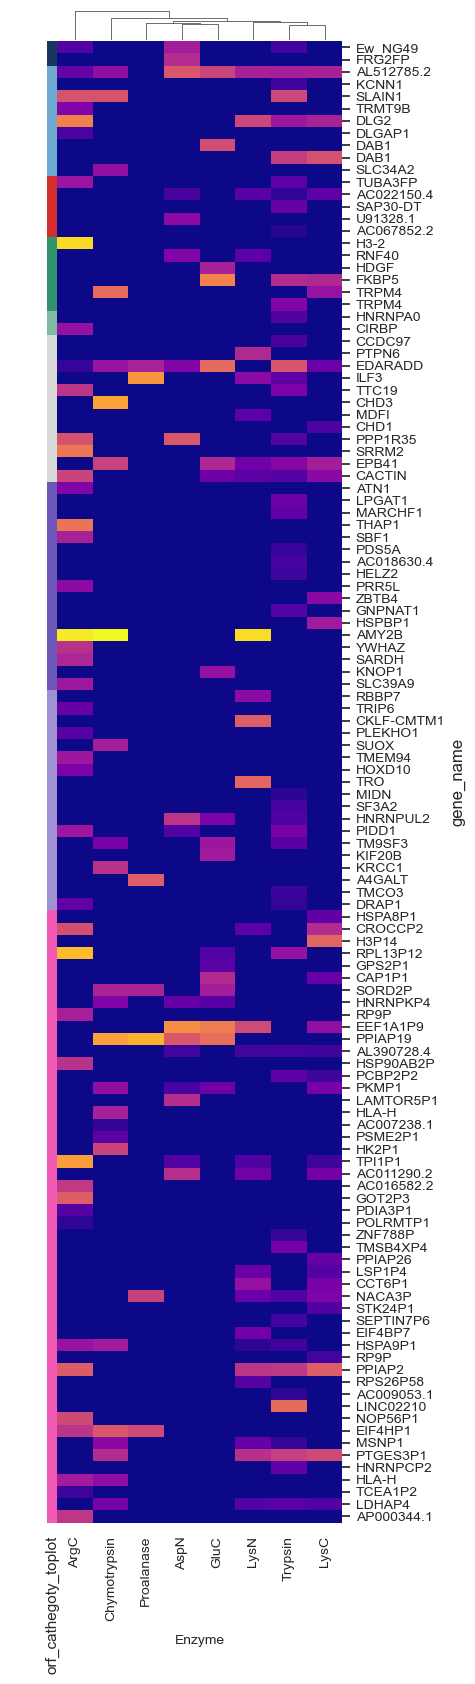

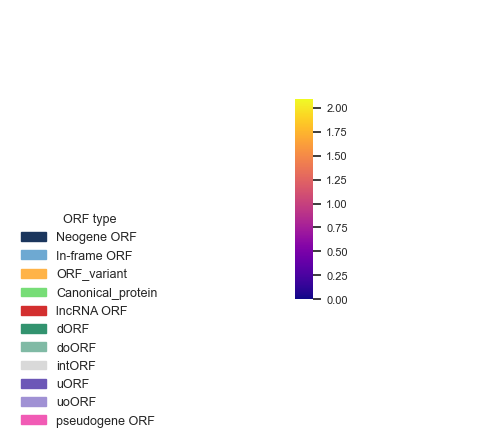

In [39]:
# Second heatmap
g = sns.clustermap(
    glue,
    cmap='plasma',
    xticklabels=True,
    yticklabels=True,
    figsize=(5, 17),
    col_cluster=True,
    row_cluster=False,
    dendrogram_ratio=(.1, .02),
    annot=False,
    row_colors=row_colors
)

# Adjust font sizes
g.ax_heatmap.set_xticklabels(g.ax_heatmap.get_xticklabels(), fontsize=10)
g.ax_heatmap.set_yticklabels(g.ax_heatmap.get_yticklabels(), fontsize=10)
g.ax_heatmap.set_xlabel("Enzyme", fontsize=10, labelpad=10)

# Remove the colorbar from the main figure
g.cax.remove()

for text in g.ax_heatmap.texts:
    text.set_fontsize(8)

# Make row colors flush
pos = g.ax_row_colors.get_position()
heatmap_pos = g.ax_heatmap.get_position()
g.ax_row_colors.set_position([
    heatmap_pos.x0 - pos.width,
    pos.y0,
    pos.width,
    pos.height
])

g.ax_heatmap.tick_params(axis='x', rotation=90)

plt.savefig('MSK_multienzyme_proteomics_ncORF_clustermap_03032026.pdf', dpi=300, bbox_inches='tight')
plt.show()

# Save legends and colorbar as a separate figure
fig_leg, (ax_leg, ax_cbar) = plt.subplots(1, 2, figsize=(6, 5), gridspec_kw={'width_ratios': [1, 0.3]})
ax_leg.axis('off')
ax_cbar.axis('off')

# Legend for ORF type
leg = ax_leg.legend(
    handles=row_patches,
    title="ORF type",
    loc="upper left",
    bbox_to_anchor=(0, 0.5),
    frameon=False,
    fontsize=9,
    title_fontsize=9
)

# Create colorbar with the same dimensions as the first one
cmap = plt.cm.plasma
norm = plt.Normalize(vmin=glue.min().min(), vmax=glue.max().max())
sm = ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

# Use the same dimensions as the first colorbar
cbar_ax = fig_leg.add_axes([0.6, 0.3, 0.03, 0.4])  # [left, bottom, width, height]
cbar = fig_leg.colorbar(sm, cax=cbar_ax)
cbar.ax.tick_params(labelsize=8)
cbar.outline.set_visible(False)  # Remove the black frame



plt.savefig('MSK_multienzyme_legend_colorbars_03032026.pdf', dpi=300, bbox_inches='tight')
plt.show()

In [69]:
meta_d = pd.read_csv("meta_with_detection.csv")
meta_d

,orf_id,ORF_ranges,Protein,gene_id,gene_biotype,gene_name,transcript_id,uniprot_gn_ids,cl_mean,ps_mean,...,result_TC106,result_RDES,detected_ip_fp,detected_ip_casanovo,detected_MSK,detected_tr,detected_DKFZ,orf_cathegoty_toplot,detected_1,detected_1_in_at_least_2_samples
0,ENSG00000159167__ENST00000290271__uORF__2__GTG,8:23854633-23854746,MAAAAAAAAAAAAAEAPVAAAASPATTTKKNPHQILT,ENSG00000159167,protein_coding,STC1,ENST00000290271,A0A0H3W641;P52823,1.187192,2.508946,...,ns,ns,False,False,False,False,False,uORF,False,False
1,ENST00000291041_23_121,16:67893276-67908682,MAAAAAAAAAAAIARRWPAEPPRRRRARRPREV,ENSG00000159792,protein_coding,PSKH1,ENST00000291041,P11801;A0A087WZT9,23.079040,17.597305,...,ns,ns,True,True,False,False,False,uORF,False,False
2,ENST00000216727_182_1099,14:23321470-23325283,MAAAAAAAAAAGAAGGRGSGPGRRRHLVPGAGGEAGEGAPGGAGDY...,ENSG00000100836,protein_coding,PABPN1,ENST00000216727,B4DEH8;Q86U42;G3V4T2,72.570950,51.634440,...,NaN,NaN,False,False,False,False,False,ORF_annotated,False,False
3,ENST00000397276_14_901,14:23321470-23324296,MAAAAAAAAAAGAAGGRGSGPGRRRHLVPGAGGEAGEGAPGGAGDY...,ENSG00000100836,protein_coding,PABPN1,ENST00000397276,B4DEH8;Q86U42;G3V4T2,71.136807,50.211111,...,ns,ns,False,False,False,False,False,ORF_variant,False,False
4,ENST00000354300_17_85,12:110583234-110583302,MAAAAAAAAAGTSVGLRRRSRRF,ENSG00000196850,protein_coding,PPTC7,ENST00000354300,Q8NI37,14.741234,14.913901,...,ns,ns,False,False,False,False,False,uORF,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
62178,ENSG00000116604__TCONS_00065632__ncRNA__9__ATT,1:156483398-156500599,MYYSPRPELRLPGVEDPPDQGRGLPALCRDNTVPPAGLEAVQKVSCRP,ENSG00000116604,protein_coding,MEF2D,TCONS_00065632,Q14814;Q05BX2,12.438524,33.178861,...,ns,ns,False,False,False,False,False,uORF,False,False
62179,ENST00000552151_8_454,12:70310970-70330470,MYYSQSSMFPHRSEKDMLASPSTSGQLSQFGASLYGQQSALGLPMR...,ENSG00000111596,protein_coding,CNOT2,ENST00000552151,F8VSK9;Q9NZN8;F8VUB4;F8W145;F8VPX5;F8VVY1;F8VV...,12.182117,23.360930,...,ns,ns,False,False,False,False,False,ORF_variant,False,False
62180,ENST00000495930_268_459,13:112875798-112875989,MYYVFIQMLSSGPAWLAIVLLVTISLLPDVLKKVLCRQLWPTATER...,ENSG00000068650,protein_coding,ATP11A,ENST00000495930,P98196;E9PEJ6;A2A3G9;A0A087WVE8,6.739418,19.103163,...,ns,ns,False,False,False,False,False,ORF_variant,False,False
62181,ENSG00000181392_ENSG00000239382__ENST000004904...,19:36010923-36013077,MYYVPDFISKEEEEYLLRQVFNAPKPKWTQLSGRKLQNWGPHCLPQ...,ENSG00000239382,protein_coding,ALKBH6,ENST00000490483,Q3KRA9;E9PI76;S4R3C7;H0YD83,10.796175,7.697037,...,ns,ns,False,False,False,False,False,ORF_variant,False,False


In [70]:
nc_msk

,Protein,AspN,GluC,Trypsin,LysC,LysN,ArgC,Chymotrypsin,Proalanase
0,A673_00003209_469_2553,0.000135,0.000097,0.000047,0.000050,0.000050,0.000014,0.000033,0.000000
58,ENST00000438427_213_782,0.000063,0.000000,0.000000,0.000019,0.000019,0.000000,0.000000,0.000000
70,ENST00000637660_1131_2294,0.000025,0.000183,0.000130,0.000017,0.000000,0.000004,0.000037,0.000049
2890,ENST00000420977_1_747,0.000010,0.000000,0.000000,0.000006,0.000010,0.000391,0.000000,0.000000
2891,ENST00000444290_37_267,0.000063,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...
9595,ENST00000447818_2495_2734,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000095,0.000000
9647,ENSG00000170004__TCONS_00371015__ncRNA__38__ATA,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000439,0.000000
9650,ENSG00000139531__ENST00000356124__uoORF__3__ACG,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000046,0.000000
9655,ENST00000347055_388_471,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000068,0.000000


In [71]:
total_proteins = nc_msk['Protein'].tolist()

In [73]:
meta_d['detected_2'] = meta_d['orf_id'].apply(lambda x: x in total_proteins)

In [74]:
enzymes = ['AspN', 'GluC', 'Trypsin', 'LysC', 'LysN', 'ArgC', 'Chymotrypsin', 'Proalanase']

In [75]:
nc_indexed = nc_msk.set_index('Protein')

meta_d['detected_2_in_at_least_2_samples'] = meta_d['orf_id'].apply(
    lambda x: (nc_indexed[enzymes].loc[x] > 0).sum() >= 2 
    if x in nc_indexed.index 
    else False
)

In [78]:
meta_d.to_csv('meta_with_detection.csv', index=False)